# QUBO Step-by-Step Formulation: Focused Thesis Walkthrough

This notebook develops the reduced scheduling QUBO term by term using explicit helper functions, so the construction can be inspected without importing the production builder.

We build:

$$
H_{\text{total}} = H_{\text{energy}} + H_{\text{assign}} + H_{\text{GPU}} + H_{\text{peak}}
$$

The main walkthrough uses fixed/exogenous PUE. The load-dependent PUE extension is derived at the end, after the QUBO terms and GPU-capacity alternatives have been introduced.

The tiny instance is pedagogical. It is designed to show what each term changes; it is not a performance benchmark.

## 1. Tiny Instance and Scenario Knobs

We use one cluster and four jobs over three hourly slots. One job lasts two slots; the other three last one slot each. The instance is small enough to inspect, while each penalty has a visible role.

- **Jobs:** `j1`–`j4`.
- **Horizon:** slots 0, 1, and 2; `delta_t = 1 hour`.
- **Durations:** `j1` lasts 2 slots; `j2`–`j4` last 1 slot.
- **GPU demand:** every job requires 1 GPU unit.
- **Cluster:** `c_main`, capacity 2 GPU units.
- **Power:** every job consumes 0.010 MW because every job requests one unit of the same GPU resource.
- **Effective QUBO energy prices:** 30, 36, and 42 €/MWh in slots 0, 1, and 2.
- **PUE for the main walkthrough:** fixed at 1.20.

All jobs can run on the cluster. `j1` may start in slot 0 or 1; each short job may start in any of the three slots. With positive energy costs and no assignment penalty, the minimum-energy answer is to schedule no jobs. Adding assignment penalties forces all four jobs to be selected, but can still overload the cluster. The GPU term then enforces capacity. Finally, the peak proxy can trade a small energy-cost increase for a lower concentrated-load measure.

The one-cluster example calls the resource unit a GPU unit. In the larger benchmark, the resource unit must be stated explicitly (GPU, node, or a scaled node unit) and used consistently.

In [50]:
from __future__ import annotations

import os
from dataclasses import dataclass, field
from itertools import combinations
from math import ceil, log2
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

try:
    import dimod
except ImportError:
    dimod = None

try:
    from dwave.samplers import SimulatedAnnealingSampler
except ImportError:
    SimulatedAnnealingSampler = None

jobs = pd.DataFrame([
    {"job_id": "j1", "duration": 2, "earliest_start": 0, "latest_start": 1,
     "gpu": 1, "power_mw": 0.010, "compatible_clusters": ["c_main"]},
    {"job_id": "j2", "duration": 1, "earliest_start": 0, "latest_start": 2,
     "gpu": 1, "power_mw": 0.010, "compatible_clusters": ["c_main"]},
    {"job_id": "j3", "duration": 1, "earliest_start": 0, "latest_start": 2,
     "gpu": 1, "power_mw": 0.010, "compatible_clusters": ["c_main"]},
    {"job_id": "j4", "duration": 1, "earliest_start": 0, "latest_start": 2,
     "gpu": 1, "power_mw": 0.010, "compatible_clusters": ["c_main"]},
])

clusters = pd.DataFrame([{"cluster_id": "c_main", "gpu_capacity": 2}])
hours = [0, 1, 2]
delta_t = 1.0
price = {0: 30.0, 1: 36.0, 2: 42.0}

# The main progressive construction uses fixed/exogenous PUE.
PUE_MODE = "fixed"
pue = {0: 1.20, 1: 1.20, 2: 1.20}

# Parameters used only in the final load-dependent-PUE extension.
pue_high = 1.35
pue_low = 1.15
it_load_max = float(jobs["power_mw"].sum())

weights = {
    "assignment": 200.0,
    "gpu_capacity": 80.0,
    "peak": 5000.0,
}

jobs

,job_id,duration,earliest_start,latest_start,gpu,power_mw,compatible_clusters
0,j1,2,0,1,1,0.01,[c_main]
1,j2,1,0,2,1,0.01,[c_main]
2,j3,1,0,2,1,0.01,[c_main]
3,j4,1,0,2,1,0.01,[c_main]


## 2. Basic QUBO Data Structure

A QUBO has the form:

$$
H(z) = q_0 + \sum_i q_i z_i + \sum_{i < j} q_{ij} z_i z_j
$$

The `QuboState` object stores the coefficients and variable metadata. Every function receives this state explicitly and returns or mutates it explicitly; no function depends on hidden global QUBO variables.

The QuboState containts 4 parameters:

- **Offset**: the overall offset term after multiple constraints
- **Linear**: a dictionary with one entry per variable (either assigment or slack) and the value of the coefficient as dictionary value. For each variable, each hamiltonian term will add a coefficient so the final coefficient for one variable is the sum of the contribution of each penalty
- **Quadratic**: in this case, dictionary keys are pair of interacting variables and the coefficients are updated in the same way as linear coefficients are
- **Variables**: 

The most important helper is `add_squared_penalty`. It implements a generic squared equality penalty:

$$
H_{\text{penalty}} = \lambda \left( \sum_{r \in R} a_r z_r - b \right)^2
$$

Expanding the square:

$$
\begin{aligned}
\lambda \left( \sum_{r \in R} a_r z_r - b \right)^2
&= \lambda \left[
\left(\sum_{r \in R} a_r z_r\right)^2
- 2b \sum_{r \in R} a_r z_r
+ b^2
\right] \\
&= \lambda \left[
\sum_{r \in R} a_r^2 z_r^2
+ \sum_{r \in R}\sum_{q \in R: q \ne r} a_r a_q z_r z_q
- 2b \sum_{r \in R} a_r z_r
+ b^2
\right]
\end{aligned}
$$

Because QUBO variables are binary, $z_r^2 = z_r$. Therefore:

$$
H_{\text{penalty}} =
\lambda b^2
+ \sum_{r \in R} \lambda (a_r^2 - 2ba_r) z_r
+ \sum_{r \in R}\sum_{q \in R: q \ne r} \lambda a_r a_q z_r z_q
$$

This formula writes the quadratic part as all ordered pairs with $q \ne r$. That is mathematically fine, but it counts each interaction twice: once as $(r,q)$ and once as $(q,r)$. Since a QUBO stores one coefficient per unordered pair, the code loops over each unordered pair only once and adds the combined coefficient:

$$
\lambda a_r a_q + \lambda a_q a_r = 2\lambda a_r a_q
$$

So the implementation does the same expansion as:

- `state.offset += weight * rhs * rhs`
- one loop over every variable: `add_linear(..., weight * (ai * ai - 2 * rhs * ai))`
- one loop over every unordered pair of different variables: `add_quadratic(..., 2 * weight * ai * aj)`


So every squared penalty is converted into QUBO coefficients by expanding the square and using the binary identity $z^2=z$.


### How to read `add_squared_penalty`

The function does not solve the problem and it does not decide which variables are equal to 1. It only builds the Hamiltonian coefficients that will later be evaluated by the solver.

For a penalty of the form:

$$
\lambda \left( a_1z_1 + a_2z_2 + \cdots + a_mz_m - b \right)^2
$$

`terms` is the dictionary:

$$
\{z_1:a_1, z_2:a_2, \ldots, z_m:a_m\}
$$

`rhs` is $b$, and `weight` is $\lambda$.

The function then adds three types of QUBO information:

1. **Offset**: the constant part $\lambda b^2$. This does not depend on any variable, but it is part of the energy value.

2. **Linear terms**: one coefficient for each variable $z_r$. These terms say whether selecting that variable alone helps or hurts the equality.

3. **Quadratic terms**: one coefficient for each pair of different variables $z_rz_q$. These terms represent the interaction created by selecting two variables at the same time.

This is why the same helper can implement several different constraints:

- assignment: the terms are all feasible start/cluster options of one job, all with coefficient 1, and the right-hand side is 1
- GPU capacity: the terms are active assignment variables plus binary slack variables, and the right-hand side is the cluster GPU capacity
- peak penalty: the terms are active assignment variables weighted by power, and the right-hand side is 0

So the mathematical work happens before calling the function: we decide what equality we want to penalize, express it as $\sum_r a_rz_r=b$, and then `add_squared_penalty` expands it into QUBO coefficients.


In [51]:
@dataclass
class QuboState:
    """Small didactic QUBO container."""

    linear: dict[int, float] = field(default_factory=dict)
    quadratic: dict[tuple[int, int], float] = field(default_factory=dict)
    offset: float = 0.0
    variables: list[dict] = field(default_factory=list)


def add_linear(state: QuboState, i: int, coeff: float) -> None:
    """Add q_i z_i to the QUBO."""
    if abs(coeff) > 1e-12:
        state.linear[i] = state.linear.get(i, 0.0) + float(coeff)


def add_quadratic(state: QuboState, i: int, j: int, coeff: float) -> None:
    """Add q_ij z_i z_j to the QUBO."""
    if abs(coeff) <= 1e-12:
        return
    if i == j:
        # Binary identity: z_i^2 = z_i.
        add_linear(state, i, coeff)
        return
    key = (i, j) if i < j else (j, i)
    state.quadratic[key] = state.quadratic.get(key, 0.0) + float(coeff)


def add_squared_penalty(state: QuboState, terms: dict[int, float], rhs: float, weight: float) -> None:
    """Add weight * (sum_i terms[i] z_i - rhs)^2."""
    state.offset += weight * rhs * rhs
    for i, ai in terms.items():
        add_linear(state, i, weight * (ai * ai - 2.0 * rhs * ai))
    for i, j in combinations(terms, 2):
        add_quadratic(state, i, j, 2.0 * weight * terms[i] * terms[j])


def qubo_summary(state: QuboState) -> dict:
    """Return a compact summary of the current QUBO."""
    return {
        "variables": len(state.variables),
        "linear_terms": len(state.linear),
        "quadratic_terms": len(state.quadratic),
        "offset": state.offset,
    }

state = QuboState()
qubo_summary(state)

{'variables': 0, 'linear_terms': 0, 'quadratic_terms': 0, 'offset': 0.0}

## 3. Assignment Variables

Create one variable per feasible scheduling option:

$$
x_{i,k,s} = 1
$$

if job $i$ starts on cluster $k$ at start slot $s$.

This notebook uses only one cluster, `c_main`, but we keep the cluster index in the notation because the implemented QUBO supports compatibility relations in the generic case.

Compatibility is represented directly as a job-cluster input relation:

$$
C_{i,k} \in \{0,1\}
$$

where $C_{i,k} = 1$ means job $i$ can run on cluster $k$. In this toy notebook all jobs are compatible with `c_main`, so the cluster dimension does not increase the number of options. In larger or multi-cluster variants, GPU type, software stack, data locality, or business rules can all be used upstream to build `compatible_clusters`.

A variable is created only if:

$$
C_{i,k} = 1
$$

We also need the job $i$ to be able to start at time $s$. Each job has a feasible start-time range, so the start time must be within that range.


In [52]:
def feasible_starts(job: pd.Series) -> list[int]:
    """Return feasible start slots for one job."""
    return list(range(int(job.earliest_start), int(job.latest_start) + 1))


def is_cluster_compatible(job: pd.Series, cluster: pd.Series) -> bool:
    """Return whether a job can run on a cluster according to C_{i,k}."""
    return str(cluster.cluster_id) in set(job.compatible_clusters)


def add_assignment_variables(state: QuboState, jobs_df: pd.DataFrame, clusters_df: pd.DataFrame) -> None:
    """Create x_{i,k,s} variables only for compatible job-cluster pairs."""
    for _, job in jobs_df.iterrows():
        for _, cluster in clusters_df.iterrows():
            if not is_cluster_compatible(job, cluster):
                continue
            for start in feasible_starts(job):
                state.variables.append({
                    "type": "assignment",
                    "job_id": job.job_id,
                    "cluster_id": cluster.cluster_id,
                    "start": int(start),
                    "duration": int(job.duration),
                    "gpu": float(job.gpu),
                    "power_mw": float(job.power_mw),
                })

add_assignment_variables(state, jobs, clusters)
assignment_variable_count = len(state.variables)
pd.DataFrame(state.variables)

,type,job_id,cluster_id,start,duration,gpu,power_mw
0,assignment,j1,c_main,0,2,1.0,0.01
1,assignment,j1,c_main,1,2,1.0,0.01
2,assignment,j2,c_main,0,1,1.0,0.01
3,assignment,j2,c_main,1,1,1.0,0.01
4,assignment,j2,c_main,2,1,1.0,0.01
5,assignment,j3,c_main,0,1,1.0,0.01
6,assignment,j3,c_main,1,1,1.0,0.01
7,assignment,j3,c_main,2,1,1.0,0.01
8,assignment,j4,c_main,0,1,1.0,0.01
9,assignment,j4,c_main,1,1,1.0,0.01


## 4. Activity Coefficient

The activity coefficient is precomputed data, not a decision variable:

$$
a_{i,s,t} =
\begin{cases}
1, & s \le t < s + d_i \\
0, & \text{otherwise}
\end{cases}
$$


This coefficient indicates if job is starting at time s (with s being an available a feasible start time for job i) is still active at time t. This is critical for calculating hourly energy consumption and GPU requirements. The GPU requirement and energy consumption of one job are observed along the whole job duration and not only at start time

In [53]:
def is_active(start: int, duration: int, hour: int) -> bool:
    """Return whether a job starting at `start` is active at `hour`."""
    return start <= hour < start + duration


def activity_table(state: QuboState, hours: list[int]) -> pd.DataFrame:
    """Build a readable activity table for assignment variables."""
    rows = []
    for idx, var in enumerate(state.variables):
        if var["type"] != "assignment":
            continue
        for t in hours:
            rows.append({
                "var": idx,
                "job": var["job_id"],
                "start": var["start"],
                "hour": t,
                "active": int(is_active(var["start"], var["duration"], t)),
            })
    return pd.DataFrame(rows)

activity_table(state, hours).head(20)

,var,job,start,hour,active
0,0,j1,0,0,1
1,0,j1,0,1,1
2,0,j1,0,2,0
3,1,j1,1,0,0
4,1,j1,1,1,1
5,1,j1,1,2,1
6,2,j2,0,0,1
7,2,j2,0,1,0
8,2,j2,0,2,0
9,3,j2,1,0,0


### 4.1 D-Wave Simulator and Validation Helpers

The next helper functions are not part of any specific Hamiltonian term. They convert the didactic QUBO into a `dimod.BinaryQuadraticModel`, solve it with D-Wave Ocean's simulated annealing sampler (`dwave.samplers.SimulatedAnnealingSampler`), and validate the decoded schedule after each progressive modeling step.

This uses a D-Wave-style sampler interface over the BQM rather than exhaustive search over all binary strings.

### Role of each helper

- **`clone_state_with_same_variables`** creates an independent QUBO with the same assignment-variable metadata but no coefficients. It lets us test one Hamiltonian term without modifying a previous experiment.
- **`qubo_energy`** evaluates the numerical QUBO energy of one binary sample from the stored offset, linear coefficients, and quadratic coefficients. It does not solve or validate the schedule.
- **`to_dimod_bqm`** converts the didactic `QuboState` into the `BinaryQuadraticModel` representation accepted by D-Wave Ocean samplers.
- **`decode_schedule`** keeps selected assignment variables and translates their metadata into a readable schedule. Selected slack bits are intentionally excluded because they are auxiliary encoding variables, not job executions.
- **`solve_with_dwave_simulator`** sends the BQM to `SimulatedAnnealingSampler`, requests repeated reads, selects the lowest-energy returned sample, and decodes it. This is classical simulated annealing through the D-Wave API, not quantum hardware.
- **`assignment_validation`** counts how many times each job appears and checks the exactly-once requirement independently of QUBO energy.
- **`gpu_usage_validation`** reconstructs active resource usage for every cluster-slot and reports physical capacity excess. This validation uses the decoded schedule, not the slack-bit values.
- **`plot_schedule_grid`** draws the decoded schedule as a job-by-time grid. Multi-slot jobs occupy every slot in which they remain active, and slot labels include energy prices.
- **`solve_and_validate`** orchestrates the preceding helpers: solve, decode, validate assignment, validate GPU capacity, summarize the QUBO, and plot the resulting schedule.


In [54]:
def clone_state_with_same_variables(source: QuboState) -> QuboState:
    """Create a clean QUBO state with the same variable metadata and no coefficients."""
    return QuboState(variables=[dict(variable) for variable in source.variables])


def qubo_energy(state: QuboState, sample: dict[int, int]) -> float:
    """Evaluate QUBO energy for one binary sample."""
    value = state.offset
    value += sum(coeff * sample.get(i, 0) for i, coeff in state.linear.items())
    value += sum(coeff * sample.get(i, 0) * sample.get(j, 0) for (i, j), coeff in state.quadratic.items())
    return float(value)


def to_dimod_bqm(state: QuboState):
    """Convert the didactic QUBO into a dimod BinaryQuadraticModel."""
    if dimod is None:
        raise ImportError("dimod is not installed")

    bqm = dimod.BinaryQuadraticModel({}, {}, state.offset, dimod.BINARY)
    for i, coeff in state.linear.items():
        bqm.add_variable(i, coeff)
    for (i, j), coeff in state.quadratic.items():
        bqm.add_interaction(i, j, coeff)
    return bqm


def decode_schedule(state: QuboState, sample: dict[int, int]) -> pd.DataFrame:
    """Decode selected assignment variables into a schedule table."""
    rows = []
    for idx, bit in sample.items():
        if bit != 1:
            continue
        var = state.variables[idx]
        if var["type"] == "assignment":
            rows.append({"var": idx, **var})
    columns = ["var", "type", "job_id", "cluster_id", "start", "duration", "gpu", "power_mw"]
    return pd.DataFrame(rows, columns=columns)


def solve_with_dwave_simulator(state: QuboState, reads: int = 5000, seed: int = 42) -> dict:
    """Solve the current QUBO with D-Wave Ocean's simulated annealing sampler."""
    if SimulatedAnnealingSampler is None:
        raise ImportError("dwave.samplers is not installed; install dwave-samplers to run the D-Wave simulator")

    bqm = to_dimod_bqm(state)
    sampleset = SimulatedAnnealingSampler().sample(
        bqm,
        num_reads=reads,
        seed=seed,
    )
    best = sampleset.first
    sample = {int(variable): int(value) for variable, value in best.sample.items()}
    return {
        "energy": float(best.energy),
        "sample": sample,
        "schedule": decode_schedule(state, sample),
        "sampleset": sampleset,
        "solver": "dwave.samplers.SimulatedAnnealingSampler",
        "reads": reads,
        "seed": seed,
    }


def assignment_validation(schedule_df: pd.DataFrame, jobs_df: pd.DataFrame) -> pd.DataFrame:
    """Report how many times each job appears in the decoded schedule."""
    assigned = schedule_df["job_id"].value_counts() if not schedule_df.empty else pd.Series(dtype=int)
    rows = []
    for job_id in jobs_df["job_id"]:
        count = int(assigned.get(job_id, 0))
        rows.append({
            "job_id": job_id,
            "assignments": count,
            "valid_exactly_once": count == 1,
        })
    return pd.DataFrame(rows)


def gpu_usage_validation(schedule_df: pd.DataFrame, clusters_df: pd.DataFrame, hours: list[int]) -> pd.DataFrame:
    """Report GPU usage and capacity violations by cluster and time."""
    rows = []
    for cluster in clusters_df.itertuples(index=False):
        for t in hours:
            used = 0.0
            if not schedule_df.empty:
                for assignment in schedule_df.itertuples(index=False):
                    if assignment.cluster_id != cluster.cluster_id:
                        continue
                    if is_active(int(assignment.start), int(assignment.duration), int(t)):
                        used += float(assignment.gpu)
            capacity = float(cluster.gpu_capacity)
            rows.append({
                "cluster_id": cluster.cluster_id,
                "hour": t,
                "gpu_used": used,
                "gpu_capacity": capacity,
                "gpu_violation": max(0.0, used - capacity),
            })
    return pd.DataFrame(rows)


def plot_schedule_grid(
    schedule_df: pd.DataFrame,
    jobs_df: pd.DataFrame,
    hours: list[int],
    title: str,
    price_by_hour: dict[int, float] | None = None,
) -> None:
    """Plot active job slots in a compact job-by-time schedule grid."""
    fig, ax = plt.subplots(figsize=(8.0, 3.2))
    job_ids = list(jobs_df["job_id"])
    job_to_y = {job_id: position for position, job_id in enumerate(job_ids)}

    for x in range(len(hours) + 1):
        ax.axvline(min(hours) + x - 0.5, color="#d0d5dd", linewidth=0.8, zorder=0)
    for y in range(len(job_ids) + 1):
        ax.axhline(y - 0.5, color="#d0d5dd", linewidth=0.8, zorder=0)

    if not schedule_df.empty:
        for assignment in schedule_df.itertuples(index=False):
            y = job_to_y.get(assignment.job_id)
            if y is None:
                continue
            active_hours = [
                hour for hour in hours
                if is_active(int(assignment.start), int(assignment.duration), int(hour))
            ]
            for hour in active_hours:
                ax.add_patch(plt.Rectangle(
                    (hour - 0.45, y - 0.38), 0.90, 0.76,
                    facecolor="#176b87", edgecolor="#0b4658",
                    linewidth=1.5, alpha=0.88,
                ))
            if active_hours:
                ax.text(
                    active_hours[0], y, f"start={int(assignment.start)}",
                    ha="center", va="center", color="white", fontsize=8,
                )

    labels = [f"slot {hour}" for hour in hours]
    if price_by_hour is not None:
        labels = [f"slot {hour}\nEUR {price_by_hour[hour]:.0f}/MWh" for hour in hours]
    ax.set_xticks(hours)
    ax.set_xticklabels(labels)
    ax.set_yticks(range(len(job_ids)))
    ax.set_yticklabels(job_ids)
    ax.set_xlim(min(hours) - 0.5, max(hours) + 0.5)
    ax.set_ylim(len(job_ids) - 0.5, -0.5)
    ax.set_xlabel("Time slot")
    ax.set_ylabel("Job")
    ax.set_title(title)
    ax.set_facecolor("#f8fafc")
    for spine in ax.spines.values():
        spine.set_visible(False)
    plt.tight_layout()
    plt.show()


def solve_and_validate(
    label: str,
    state: QuboState,
    jobs_df: pd.DataFrame,
    clusters_df: pd.DataFrame,
    hours: list[int],
    price_by_hour: dict[int, float] | None = None,
) -> dict:
    """Solve, decode, validate, and plot one progressive QUBO stage."""
    result = solve_with_dwave_simulator(state)
    schedule = result["schedule"]
    assignment_check = assignment_validation(schedule, jobs_df)
    gpu_check = gpu_usage_validation(schedule, clusters_df, hours)
    summary = {
        "stage": label,
        "solver": result["solver"],
        "reads": result["reads"],
        "energy": result["energy"],
        **qubo_summary(state),
        "scheduled_jobs": 0 if schedule.empty else int(schedule["job_id"].nunique()),
        "total_assignments": len(schedule),
        "assignment_violations": int((~assignment_check["valid_exactly_once"]).sum()),
        "gpu_violation_total": float(gpu_check["gpu_violation"].sum()),
    }
    print('Summary for stage:', label)
    display(pd.DataFrame([summary]))
    print('Schedule for stage:', label)
    display(schedule)
    print('Assignment check for stage:', label)
    display(assignment_check)
    print('GPU usage check for stage:', label)
    display(gpu_check)
    plot_schedule_grid(
        schedule, jobs_df, hours,
        title=f"Schedule after {label}",
        price_by_hour=price_by_hour,
    )
    return {
        **result,
        "summary": summary,
        "assignment_check": assignment_check,
        "gpu_check": gpu_check,
    }


## 5. Energy Cost Term: Cost-Only Validation

We start with the fixed/exogenous PUE energy term:

$$
H_{\text{energy}} = \sum_{i,k,s} E_{i,k,s} x_{i,k,s}
$$

where:

$$
E_{i,k,s} = \sum_t c_t \Delta t\, \mathrm{PUE}_t\, p_i\, a_{i,s,t}.
$$

Here $c_t$ is the effective QUBO energy price, $p_i$ is the IT power of job $i$, and $a_{i,s,t}$ indicates whether a job starting at $s$ is active at slot $t$. This is linear in the assignment variables: every option receives the energy cost it would incur if selected.

This term alone does **not** require jobs to be scheduled. Since the coefficients are positive, the minimum is obtained by setting every assignment variable to zero. That is expected; the assignment constraint is added in the next section.

The load-dependent PUE version also remains QUBO-compatible under the affine model used here, but introduces quadratic energy interactions. We defer its derivation and coefficient demonstration to the final section.

Summary for stage: 1_cost_only


,stage,solver,reads,energy,variables,linear_terms,quadratic_terms,offset,scheduled_jobs,total_assignments,assignment_violations,gpu_violation_total
0,1_cost_only,dwave.samplers.SimulatedAnnealingSampler,5000,-8.881784e-16,11,11,0,0.0,0,0,4,0.0


Schedule for stage: 1_cost_only


,var,type,job_id,cluster_id,start,duration,gpu,power_mw


Assignment check for stage: 1_cost_only


,job_id,assignments,valid_exactly_once
0,j1,0,False
1,j2,0,False
2,j3,0,False
3,j4,0,False


GPU usage check for stage: 1_cost_only


,cluster_id,hour,gpu_used,gpu_capacity,gpu_violation
0,c_main,0,0.0,2.0,0.0
1,c_main,1,0.0,2.0,0.0
2,c_main,2,0.0,2.0,0.0


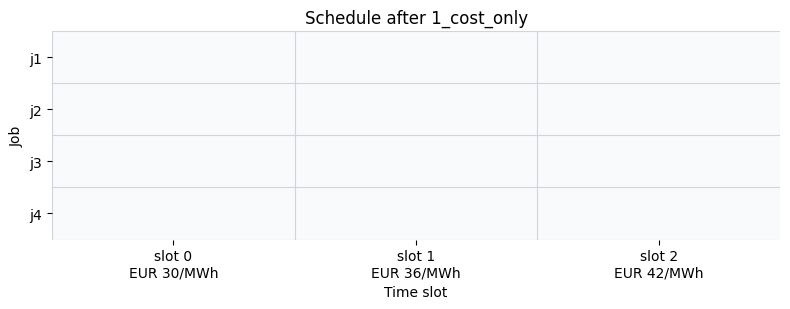

In [55]:
def active_assignment_terms(state: QuboState, hours: list[int], hour: int, coefficient_field: str) -> dict[int, float]:
    """Return coefficients for assignment variables active in one hour."""
    terms = {}
    for idx, var in enumerate(state.variables):
        if var["type"] != "assignment":
            continue
        if is_active(var["start"], var["duration"], hour):
            terms[idx] = float(var[coefficient_field])
    return terms


def add_energy_cost(
    state: QuboState,
    hours: list[int],
    price: dict[int, float],
    delta_t: float,
    pue_mode: str,
    fixed_pue: dict[int, float] | None = None,
    pue_high: float | None = None,
    pue_low: float | None = None,
    it_load_max: float | None = None,
) -> None:
    """Add either fixed-PUE or load-dependent-PUE energy cost."""
    if pue_mode == "fixed":
        if fixed_pue is None:
            raise ValueError("fixed_pue is required when pue_mode='fixed'")
        for t in hours:
            active_power = active_assignment_terms(state, hours, t, "power_mw")
            for idx, power_mw in active_power.items():
                add_linear(state, idx, price[t] * delta_t * fixed_pue[t] * power_mw)
        return

    if pue_mode == "load_dependent":
        if pue_high is None or pue_low is None or it_load_max is None:
            raise ValueError("pue_high, pue_low, and it_load_max are required for load-dependent PUE")
        beta = pue_high - pue_low
        for t in hours:
            active_power = active_assignment_terms(state, hours, t, "power_mw")

            # Linear part: c_t dt PUE_high L_t.
            for idx, power_mw in active_power.items():
                add_linear(state, idx, price[t] * delta_t * pue_high * power_mw)

            # Quadratic part: - c_t dt beta / Lmax * L_t^2.
            factor = -price[t] * delta_t * beta / it_load_max
            for idx, power_mw in active_power.items():
                add_linear(state, idx, factor * power_mw * power_mw)
            for i, j in combinations(active_power, 2):
                add_quadratic(state, i, j, 2.0 * factor * active_power[i] * active_power[j])
        return

    raise ValueError("pue_mode must be 'fixed' or 'load_dependent'")

state = clone_state_with_same_variables(state)
add_energy_cost(
    state,
    hours=hours,
    price=price,
    delta_t=delta_t,
    pue_mode=PUE_MODE,
    fixed_pue=pue,
    pue_high=pue_high,
    pue_low=pue_low,
    it_load_max=it_load_max,
)

cost_only_result = solve_and_validate(
    "1_cost_only", state, jobs, clusters, hours, price_by_hour=price
)


In [56]:
pd.DataFrame([{"var": i, "linear_coeff": coeff, **state.variables[i]} for i, coeff in sorted(state.linear.items())])

,var,linear_coeff,type,job_id,cluster_id,start,duration,gpu,power_mw
0,0,0.792,assignment,j1,c_main,0,2,1.0,0.01
1,1,0.936,assignment,j1,c_main,1,2,1.0,0.01
2,2,0.360,assignment,j2,c_main,0,1,1.0,0.01
3,3,0.432,assignment,j2,c_main,1,1,1.0,0.01
4,4,0.504,assignment,j2,c_main,2,1,1.0,0.01
5,5,0.360,assignment,j3,c_main,0,1,1.0,0.01
6,6,0.432,assignment,j3,c_main,1,1,1.0,0.01
7,7,0.504,assignment,j3,c_main,2,1,1.0,0.01
8,8,0.360,assignment,j4,c_main,0,1,1.0,0.01
9,9,0.432,assignment,j4,c_main,1,1,1.0,0.01


## 6. Assignment Constraint: Force Every Job Once

Each job must be assigned exactly once:

$$
\sum_{(k,s) \in \mathcal{A}_i} x_{i,k,s} = 1
$$

where $\mathcal{A}_i$ is the set of feasible cluster-start options for job $i$.

QUBO penalty:

$$
H_{\text{assign}} = \lambda_A \sum_i \left( \sum_{(k,s) \in \mathcal{A}_i} x_{i,k,s} - 1 \right)^2
$$

For one job, define $R_i=\mathcal{A}_i$ and $z_r=x_{i,k,s}$ for each option $r=(k,s)$. This is the generic squared penalty with $a_r=1$ and $b=1$:

$$
\lambda_A \left( \sum_{r \in R_i} z_r - 1 \right)^2
$$

Expansion:

$$
\begin{aligned}
\lambda_A \left( \sum_{r \in R_i} z_r - 1 \right)^2
&= \lambda_A \left[
\left(\sum_{r \in R_i} z_r\right)^2
-2\sum_{r \in R_i} z_r
+1
\right] \\
&= \lambda_A \left[
\sum_{r \in R_i} z_r^2
+2\sum_{r<q}z_rz_q
-2\sum_{r \in R_i} z_r
+1
\right] \\
&= \lambda_A \left[
1
-\sum_{r \in R_i} z_r
+2\sum_{r<q}z_rz_q
\right]
\end{aligned}
$$

The last step uses $z_r^2=z_r$.

So the coefficients added by `add_squared_penalty(..., rhs=1, weight=lambda_A)` are:

- offset: $+\lambda_A$
- linear coefficient for each assignment option of the job: $-\lambda_A$
- quadratic coefficient between every pair of different options of the same job: $+2\lambda_A$

Interpretation:

- selecting zero options gives penalty $\lambda_A$
- selecting one option gives penalty $0$
- selecting two options gives penalty $\lambda_A$
- selecting more than two options gives an even larger penalty

Validation expectation:

> Once this term is added, every job should appear exactly once. Because GPU capacity is not active yet, several jobs may still choose the same cheap time slot even if that overloads a cluster.


Summary for stage: 2_cost_plus_assignment


,stage,solver,reads,energy,variables,linear_terms,quadratic_terms,offset,scheduled_jobs,total_assignments,assignment_violations,gpu_violation_total
0,2_cost_plus_assignment,dwave.samplers.SimulatedAnnealingSampler,5000,1.872,11,11,10,800.0,4,4,0,2.0


Schedule for stage: 2_cost_plus_assignment


,var,type,job_id,cluster_id,start,duration,gpu,power_mw
0,0,assignment,j1,c_main,0,2,1.0,0.01
1,2,assignment,j2,c_main,0,1,1.0,0.01
2,5,assignment,j3,c_main,0,1,1.0,0.01
3,8,assignment,j4,c_main,0,1,1.0,0.01


Assignment check for stage: 2_cost_plus_assignment


,job_id,assignments,valid_exactly_once
0,j1,1,True
1,j2,1,True
2,j3,1,True
3,j4,1,True


GPU usage check for stage: 2_cost_plus_assignment


,cluster_id,hour,gpu_used,gpu_capacity,gpu_violation
0,c_main,0,4.0,2.0,2.0
1,c_main,1,1.0,2.0,0.0
2,c_main,2,0.0,2.0,0.0


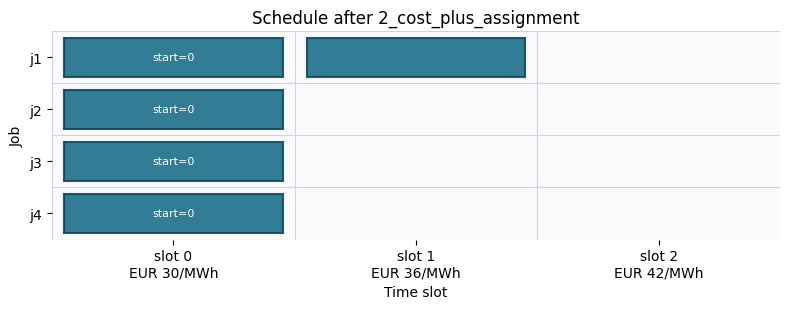

In [57]:
def add_assignment_penalty(state: QuboState, jobs_df: pd.DataFrame, weight: float) -> None:
    """Add one-hot assignment penalties, one job at a time."""
    for job_id in jobs_df["job_id"]:
        terms = {
            idx: 1.0
            for idx, var in enumerate(state.variables)
            if var["type"] == "assignment" and var["job_id"] == job_id
        }
        add_squared_penalty(state, terms, rhs=1.0, weight=weight)

add_assignment_penalty(state, jobs, weights["assignment"])
assignment_result = solve_and_validate(
    "2_cost_plus_assignment", state, jobs, clusters, hours, price_by_hour=price
)


## 7. Resource Capacity Constraint With Binary Slack: Remove Overloads

Resource demand per cluster and time:

$$
D^G_{k,t}(x) = \sum_i \sum_s g_i a_{i,s,t} x_{i,k,s}
$$

where:

- $g_i$ is the number of resource units required by job $i$
- $a_{i,s,t}$ is precomputed and equals 1 if a job starting at $s$ is active at time $t$
- only variables assigned to cluster $k$ contribute to $D^G_{k,t}(x)$

The original inequality is:

$$
D^G_{k,t}(x) \le G_k
$$

QUBO handles this by adding an unused-capacity slack variable:

$$
D^G_{k,t}(x) + Y_{k,t} = G_k
$$

The slack is binary encoded:

$$
Y_{k,t} = \sum_{b=0}^{B_k-1} 2^b y_{k,t,b}
$$

So the implemented equality is:

$$
D^G_{k,t}(x) + \sum_{b=0}^{B_k-1} 2^b y_{k,t,b} = G_k
$$

Penalty:

$$
H_{\text{GPU}} = \lambda_G \sum_{k,t} \left( D^G_{k,t}(x) + \sum_b 2^b y_{k,t,b} - G_k \right)^2
$$

For one cluster-time pair, define:

$$
D = \sum_{r \in R_{k,t}} g_r x_r,
\qquad
Y = \sum_b 2^b y_b,
\qquad
G = G_k
$$

where $R_{k,t}$ is the set of assignment variables active on cluster $k$ at time $t$. Then:

$$
\lambda_G(D+Y-G)^2
$$

Expansion by blocks:

$$
\lambda_G(D+Y-G)^2
= \lambda_G\left[D^2 + Y^2 + 2DY - 2GD - 2GY + G^2\right]
$$

Now expand each block:

$$
D^2 =
\sum_{r \in R_{k,t}} g_r^2 x_r
+ 2\sum_{r<q} g_r g_q x_r x_q
$$

$$
Y^2 =
\sum_b 4^b y_b
+ 2\sum_{b<c} 2^b 2^c y_b y_c
$$

$$
2DY = 2\sum_{r \in R_{k,t}}\sum_b g_r 2^b x_r y_b
$$

Therefore, for each cluster-time pair, the expanded QUBO is:

$$
\begin{aligned}
H_{\text{GPU},k,t} = \lambda_G \Bigg[&
G^2
+ \sum_{r \in R_{k,t}} (g_r^2 - 2Gg_r)x_r
+ \sum_b (4^b - 2G2^b)y_b \\
&+ 2\sum_{r<q} g_r g_q x_r x_q
+ 2\sum_{r \in R_{k,t}}\sum_b g_r2^b x_r y_b
+ 2\sum_{b<c}2^b2^c y_by_c
\Bigg]
\end{aligned}
$$

This is exactly the same generic `add_squared_penalty` expansion with:

- assignment terms: $a_r=g_r$
- slack terms: $a_b=2^b$
- right-hand side: $b=G_k$

Interpretation:

- if resource usage is below capacity, the slack bits can represent the unused GPUs and the penalty can be zero
- if resource usage equals capacity, slack is zero and the penalty can be zero
- if resource usage exceeds capacity, no non-negative slack value can repair the equality, so the penalty is positive

### How `add_gpu_capacity_penalty_with_slack` Builds the Penalty

The function adds one GPU-capacity penalty for each cluster-time pair \((k,t)\). Its target is:

$$
D^G_{k,t}(x) + Y_{k,t} = G_k
$$

and then it calls `add_squared_penalty` to add:

$$
\lambda_G\left(D^G_{k,t}(x)+Y_{k,t}-G_k\right)^2
$$

The code builds this equality through the `terms` dictionary.

First, it loops over clusters:

```python
for cluster in clusters_df.itertuples(index=False):
    G = int(cluster.gpu_capacity)
    bits = max(1, ceil(log2(G + 1)))
```

Here:

- `G` is the GPU capacity \(G_k\) of the current cluster.
- `bits` is the number of binary slack bits needed to represent unused GPUs from 0 to \(G_k\).

For example, if \(G_k=2\), then:

$$
B_k = \lceil \log_2(2+1) \rceil = 2
$$

so slack can be represented as:

$$
Y_{k,t}=y_{k,t,0}+2y_{k,t,1}
$$

Then the function loops over time slots:

```python
for t in hours:
    terms = {}
```

At this point, `terms` is the code representation of the left-hand side of the equality:

$$
D^G_{k,t}(x)+Y_{k,t}
$$

Each key in `terms` is a QUBO variable index. Each value is that variable's coefficient in the equality.

Next, the function scans existing assignment variables:

```python
for idx, var in enumerate(state.variables):
    if var["type"] != "assignment":
        continue
    if var["cluster_id"] != cluster.cluster_id:
        continue
    if is_active(var["start"], var["duration"], t):
        terms[idx] = float(var["gpu"])
```

This does three filters:

1. keep only assignment variables \(x_{i,k,s}\), not slack variables;
2. keep only variables assigned to the current cluster \(k\);
3. keep only variables active at the current time slot \(t\).

If an assignment option is active in this cluster-time pair, it contributes its GPU demand:

$$
\texttt{terms[idx]} = g_i
$$

So the assignment part of `terms` represents:

$$
D^G_{k,t}(x)=\sum_i\sum_s g_i a_{i,s,t}x_{i,k,s}
$$

If no assignment variable can ever be active in that cluster-time pair, the function skips the penalty:

```python
if not terms:
    continue
```

Then it creates the slack variables for unused GPUs:

```python
for b in range(bits):
    slack_idx = len(state.variables)
    state.variables.append({
        "type": "gpu_slack",
        "cluster_id": cluster.cluster_id,
        "hour": t,
        "bit": b,
        "coefficient": float(2**b),
    })
    terms[slack_idx] = float(2**b)
```

For each bit \(b\), it creates a new QUBO variable \(y_{k,t,b}\) and adds it to `terms` with coefficient \(2^b\). After this, `terms` contains both used-GPU variables and unused-GPU slack variables.

For example, if two active assignment variables use one GPU each and the cluster capacity is 2, `terms` may look like:

```python
{
    0: 1.0,  # x1 uses 1 GPU
    3: 1.0,  # x2 uses 1 GPU
    8: 1.0,  # slack bit y0
    9: 2.0,  # slack bit y1
}
```

This dictionary represents:

$$
x_1+x_2+y_0+2y_1
$$

Finally, the function calls:

```python
add_squared_penalty(state, terms, rhs=float(G), weight=weight)
```

which adds:

$$
\lambda_G\left(x_1+x_2+y_0+2y_1-G_k\right)^2
$$

to the QUBO coefficient dictionaries.

So the code-level interpretation is:

- `terms` builds the left-hand side \(D^G_{k,t}(x)+Y_{k,t}\);
- `rhs=float(G)` is the right-hand side \(G_k\);
- `weight` is \(\lambda_G\);
- `add_squared_penalty` expands the square into offset, linear coefficients, and quadratic coefficients.

Validation expectation:

> The schedule should still assign every job exactly once, but it should no longer exceed the capacity of the single cluster at any time. In this toy instance, all four jobs can run on `c_main`, but the cluster has capacity 2, so the capacity penalty should prevent scheduling more than two jobs in the same time slot.


### Alternative: Slack-Free Unbalanced Penalty

The starting point is the same physical inequality:

$$
D^G_{k,t}(x) \leq G_k.
$$

Instead of turning it into an equality with binary slack bits, define the **capacity margin**:

$$
h_{k,t}(x)=G_k-D^G_{k,t}(x).
$$

The constraint is satisfied when $h_{k,t}(x)\geq0$ and violated when $h_{k,t}(x)<0$. The unbalanced penalty applies a linear and a quadratic term directly to this margin:

$$
P_{k,t}^{\mathrm{unb}}(x)
=-\lambda_Lh_{k,t}(x)+\lambda_Qh_{k,t}(x)^2,
\qquad \lambda_L,\lambda_Q>0.
$$

Summing over every cluster and time slot gives the GPU-capacity Hamiltonian:

$$
H_{\mathrm{GPU}}^{\mathrm{unb}}(x)
=\sum_k\sum_t\left[
-\lambda_L\left(G_k-D^G_{k,t}(x)\right)
+\lambda_Q\left(G_k-D^G_{k,t}(x)\right)^2
\right].
$$

The complete model then uses:

$$
H_{\mathrm{problem}}
=H_{\mathrm{energy}}+H_{\mathrm{assignment}}
+H_{\mathrm{GPU}}^{\mathrm{unb}}
\;(+H_{\mathrm{peak}}).
$$

#### Expansion for one cluster-time pair

For one pair $(k,t)$, write:

$$
D=\sum_{r\in R_{k,t}}g_rx_r,
\qquad G=G_k.
$$

Substitution and expansion give:

$$
\begin{aligned}
P^{\mathrm{unb}}(D)
&=-\lambda_L(G-D)+\lambda_Q(G-D)^2\\
&=-\lambda_LG+\lambda_LD
+\lambda_QG^2-2\lambda_QGD+\lambda_QD^2.
\end{aligned}
$$

Because $x_r$ is binary, $x_r^2=x_r$, and therefore:

$$
D^2=\sum_{r\in R_{k,t}}g_r^2x_r
+2\sum_{r<q}g_rg_qx_rx_q.
$$

The final QUBO contribution is:

$$
\begin{aligned}
P_{k,t}^{\mathrm{unb}}(x)=
&\underbrace{\lambda_QG^2-\lambda_LG}_{\text{constant offset}}\\
&+\sum_{r\in R_{k,t}}
\underbrace{\left[\lambda_Lg_r+\lambda_Q(g_r^2-2Gg_r)\right]}
_{\text{linear coefficient}}x_r\\
&+2\lambda_Q\sum_{r<q}
\underbrace{g_rg_q}_{\text{interaction strength}}x_rx_q.
\end{aligned}
$$

This contains only assignment variables. It introduces no slack variables, assignment-to-slack couplers, or slack-to-slack couplers.

#### Why it is unbalanced

- If $D>G$, then $h<0$: both terms are positive, so overload is penalized.
- If $D\leq G$, then $h\geq0$: the linear term is negative and the quadratic term is positive, so feasible loads do not all receive equal penalty.
- The continuous minimum occurs at:

$$
h^*=\frac{\lambda_L}{2\lambda_Q},
\qquad
D^*=G-\frac{\lambda_L}{2\lambda_Q}.
$$

Thus, the ratio $\lambda_L/\lambda_Q$ controls the preferred unused capacity. This is not an exact zero-penalty representation of every feasible load; it is a calibrated surrogate that reduces QUBO size but changes the energy landscape. Its weights must be strong enough to discourage overloads relative to the energy and peak terms without overwhelming the rest of the Hamiltonian.

Summary for stage: 3_cost_assignment_gpu_capacity


,stage,solver,reads,energy,variables,linear_terms,quadratic_terms,offset,scheduled_jobs,total_assignments,assignment_violations,gpu_violation_total
0,3_cost_assignment_gpu_capacity,dwave.samplers.SimulatedAnnealingSampler,5000,2.088,17,17,60,1760.0,4,4,0,0.0


Schedule for stage: 3_cost_assignment_gpu_capacity


,var,type,job_id,cluster_id,start,duration,gpu,power_mw
0,0,assignment,j1,c_main,0,2,1.0,0.01
1,2,assignment,j2,c_main,0,1,1.0,0.01
2,6,assignment,j3,c_main,1,1,1.0,0.01
3,10,assignment,j4,c_main,2,1,1.0,0.01


Assignment check for stage: 3_cost_assignment_gpu_capacity


,job_id,assignments,valid_exactly_once
0,j1,1,True
1,j2,1,True
2,j3,1,True
3,j4,1,True


GPU usage check for stage: 3_cost_assignment_gpu_capacity


,cluster_id,hour,gpu_used,gpu_capacity,gpu_violation
0,c_main,0,2.0,2.0,0.0
1,c_main,1,2.0,2.0,0.0
2,c_main,2,1.0,2.0,0.0


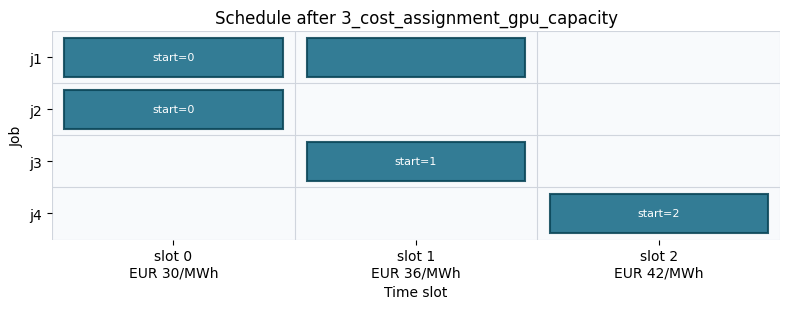

{'slack_variables_added': 6,
 'variables': 17,
 'linear_terms': 17,
 'quadratic_terms': 60,
 'offset': 1760.0}

In [58]:
def add_gpu_capacity_penalty_with_slack(
    state: QuboState,
    clusters_df: pd.DataFrame,
    hours: list[int],
    weight: float,
) -> None:
    """Add GPU capacity penalties using binary unused-GPU slack bits."""
    for cluster in clusters_df.itertuples(index=False):
        G = int(cluster.gpu_capacity)
        bits = max(1, ceil(log2(G + 1)))
        for t in hours:
            terms = {}
            for idx, var in enumerate(state.variables):
                if var["type"] != "assignment":
                    continue
                if var["cluster_id"] != cluster.cluster_id:
                    continue
                if is_active(var["start"], var["duration"], t):
                    terms[idx] = float(var["gpu"])

            if not terms:
                continue

            for b in range(bits):
                slack_idx = len(state.variables)
                state.variables.append({
                    "type": "gpu_slack",
                    "cluster_id": cluster.cluster_id,
                    "hour": t,
                    "bit": b,
                    "coefficient": float(2**b),
                })
                terms[slack_idx] = float(2**b)

            add_squared_penalty(state, terms, rhs=float(G), weight=weight)

variables_before_slack = len(state.variables)
add_gpu_capacity_penalty_with_slack(state, clusters, hours, weights["gpu_capacity"])
slack_variable_count = len(state.variables) - variables_before_slack

gpu_capacity_result = solve_and_validate(
    "3_cost_assignment_gpu_capacity", state, jobs, clusters, hours, price_by_hour=price
)
{"slack_variables_added": slack_variable_count, **qubo_summary(state)}


In [59]:
pd.DataFrame(state.variables).query("type == 'gpu_slack'")

,type,job_id,cluster_id,start,duration,gpu,power_mw,hour,bit,coefficient
11,gpu_slack,NaN,c_main,NaN,NaN,NaN,NaN,0.0,0.0,1.0
12,gpu_slack,NaN,c_main,NaN,NaN,NaN,NaN,0.0,1.0,2.0
13,gpu_slack,NaN,c_main,NaN,NaN,NaN,NaN,1.0,0.0,1.0
14,gpu_slack,NaN,c_main,NaN,NaN,NaN,NaN,1.0,1.0,2.0
15,gpu_slack,NaN,c_main,NaN,NaN,NaN,NaN,2.0,0.0,1.0
16,gpu_slack,NaN,c_main,NaN,NaN,NaN,NaN,2.0,1.0,2.0


### 7.1 Slack and Slack-Free GPU Formulations Side by Side

The slack formulation is an exact encoding of $D\leq G$: every load from zero through capacity can be matched by a non-negative slack value. The slack-free alternative uses the Hamiltonian derived above. For this toy, $\lambda_L=1$ and $\lambda_Q=1$, so its preferred continuous margin is $h^*=0.5$ GPU units. Since the actual GPU load is discrete, the table shows how this preference is distributed over integer loads before solving. The comparison is therefore between an exact encoding with extra variables and a smaller calibrated surrogate with a different penalty landscape.

,GPU load,capacity,slack encoding: minimum penalty,slack-free unbalanced penalty,feasible by capacity rule
0,0,2,0.0,2.0,True
1,1,2,0.0,0.0,True
2,2,2,0.0,0.0,True
3,3,2,inf,2.0,False


Summary for stage: GPU capacity: slack-free unbalanced


,stage,solver,reads,energy,variables,linear_terms,quadratic_terms,offset,scheduled_jobs,total_assignments,assignment_violations,gpu_violation_total
0,GPU capacity: slack-free unbalanced,dwave.samplers.SimulatedAnnealingSampler,5000,2.088,11,11,31,806.0,4,4,0,0.0


Schedule for stage: GPU capacity: slack-free unbalanced


,var,type,job_id,cluster_id,start,duration,gpu,power_mw
0,0,assignment,j1,c_main,0,2,1.0,0.01
1,3,assignment,j2,c_main,1,1,1.0,0.01
2,7,assignment,j3,c_main,2,1,1.0,0.01
3,8,assignment,j4,c_main,0,1,1.0,0.01


Assignment check for stage: GPU capacity: slack-free unbalanced


,job_id,assignments,valid_exactly_once
0,j1,1,True
1,j2,1,True
2,j3,1,True
3,j4,1,True


GPU usage check for stage: GPU capacity: slack-free unbalanced


,cluster_id,hour,gpu_used,gpu_capacity,gpu_violation
0,c_main,0,2.0,2.0,0.0
1,c_main,1,2.0,2.0,0.0
2,c_main,2,1.0,2.0,0.0


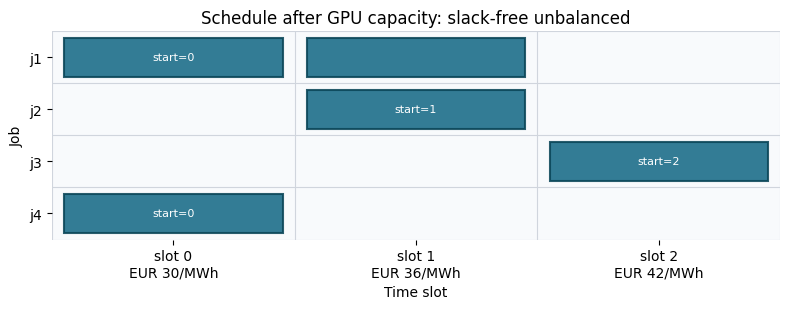

,formulation,variables,linear_terms,quadratic_terms,offset,variables_total,slack_variables
0,binary slack,17,17,60,1760.0,17,6
1,slack-free unbalanced,11,11,31,806.0,11,0


In [60]:
def add_gpu_capacity_penalty_without_slack(
    state: QuboState,
    clusters_df: pd.DataFrame,
    hours: list[int],
    linear_weight: float,
    quadratic_weight: float,
) -> None:
    """Add the slack-free unbalanced GPU penalty used in the comparison."""
    for cluster in clusters_df.itertuples(index=False):
        capacity = float(cluster.gpu_capacity)
        for t in hours:
            load_terms = {}
            for idx, var in enumerate(state.variables):
                if var["type"] != "assignment":
                    continue
                if var["cluster_id"] != cluster.cluster_id:
                    continue
                if is_active(int(var["start"]), int(var["duration"]), int(t)):
                    load_terms[idx] = float(var["gpu"])
            if not load_terms:
                continue

            # P(D) = -linear_weight*G + linear_weight*D
            #        + quadratic_weight*(D-G)^2
            state.offset -= linear_weight * capacity
            for idx, demand in load_terms.items():
                add_linear(state, idx, linear_weight * demand)
            add_squared_penalty(
                state, load_terms, rhs=capacity, weight=quadratic_weight
            )


def gpu_penalty_profile(capacity: int, linear_weight: float, quadratic_weight: float) -> pd.DataFrame:
    """Compare exact slack feasibility with the selected unbalanced profile."""
    rows = []
    for load in range(capacity + 2):
        slack_feasible = load <= capacity
        slack_penalty = 0.0 if slack_feasible else float("inf")
        unbalanced = (
            -linear_weight * capacity
            + linear_weight * load
            + quadratic_weight * (load - capacity) ** 2
        )
        rows.append({
            "GPU load": load,
            "capacity": capacity,
            "slack encoding: minimum penalty": slack_penalty,
            "slack-free unbalanced penalty": unbalanced,
            "feasible by capacity rule": slack_feasible,
        })
    return pd.DataFrame(rows)

LINEAR_GPU_WEIGHT = 1.0
QUADRATIC_GPU_WEIGHT = 1.0

display(gpu_penalty_profile(
    int(clusters.iloc[0].gpu_capacity), LINEAR_GPU_WEIGHT, QUADRATIC_GPU_WEIGHT
))

# Build a separate QUBO so the slack and no-slack states remain independent.
no_slack_state = QuboState(variables=[dict(v) for v in state.variables if v["type"] == "assignment"])
add_energy_cost(
    no_slack_state, hours, price, delta_t, "fixed", fixed_pue=pue
)
add_assignment_penalty(no_slack_state, jobs, weights["assignment"])
add_gpu_capacity_penalty_without_slack(
    no_slack_state, clusters, hours, LINEAR_GPU_WEIGHT, QUADRATIC_GPU_WEIGHT
)
no_slack_gpu_result = solve_and_validate(
    "GPU capacity: slack-free unbalanced", no_slack_state, jobs, clusters, hours,
    price_by_hour=price,
)

pd.DataFrame([
    {"formulation": "binary slack", **qubo_summary(state),
     "variables_total": len(state.variables),
     "slack_variables": sum(v["type"] == "gpu_slack" for v in state.variables)},
    {"formulation": "slack-free unbalanced", **qubo_summary(no_slack_state),
     "variables_total": len(no_slack_state.variables),
     "slack_variables": 0},
])

## 8. Peak Penalty: Encourage Load Spreading

### Why use a square as a proxy for maximum load?

A physical peak-charge objective would normally depend on the maximum facility load over the scheduling horizon:

$$
P_{\max}(x)=\max_t P_t^{\mathrm{facility}}(x).
$$

The $\max$ operator is not directly a quadratic polynomial in binary variables. In a MILP, it can be represented with an auxiliary variable $P_{\max}$ and constraints $P_{\max}\geq P_t^{\mathrm{facility}}$ for every $t$. A standard QUBO cannot introduce that continuous maximum variable and those inequalities without additional binary encodings and penalties, which would increase both the number of variables and the calibration burden.

We therefore use the squared-load sum as a compact smoothing proxy:

$$
H_{\mathrm{peak}}(x)
=\lambda_P\sum_t\left(P_t^{\mathrm{facility}}(x)\right)^2.
$$

The square gives disproportionate weight to high-load slots. For example, if two equal units of load can be placed either together or separately:

$$
2^2+0^2=4
\quad>\quad
1^2+1^2=2.
$$

Both schedules process the same total load, but the concentrated schedule receives twice the proxy penalty. More generally, when total required work is fixed, minimizing the sum of squares favors distributing that work across time and usually reduces the maximum load. The relationship with the true peak is:

$$
\max_t P_t
\leq \sqrt{\sum_t P_t^2}
\leq \sqrt{|T|}\max_t P_t.
$$

Thus, reducing the squared-load sum also reduces an upper measure associated with the peak, but the two objectives are not identical. The proxy penalizes load in every slot, not only the single largest slot. Its coefficient $\lambda_P$ therefore controls a trade-off: a small value has little scheduling effect, while a large value may move jobs away from cheap energy periods simply to flatten the profile. Final comparisons must report the actual decoded maximum load in addition to the QUBO proxy value.

For fixed PUE, we can use squared facility load:

$$
H_{\text{peak}}^{\text{PUE-fixed}} = \lambda_P \sum_t \left( \mathrm{PUE}_t \, L_t^{\mathrm{IT}}(x) \right)^2
$$

where:

$$
L_t^{\mathrm{IT}}(x) = \sum_{i,k,s} p_i a_{i,s,t}x_{i,k,s}
$$

For one time slot, define $r=(i,k,s)$ and:

$$
\ell_{r,t}=\mathrm{PUE}_t p_i a_{i,s,t}
$$

Then the peak term for that time slot is:

$$
\lambda_P \left(\sum_r \ell_{r,t}x_r\right)^2
$$

This is the generic squared penalty with right-hand side zero: $b=0$. Therefore there is no offset and no negative linear term.

Expansion:

$$
\lambda_P \left(\sum_r \ell_{r,t}x_r\right)^2
= \lambda_P \left[
\sum_r \ell_{r,t}^2x_r
+2\sum_{r<q}\ell_{r,t}\ell_{q,t}x_rx_q
\right]
$$

So `add_squared_penalty(..., rhs=0, weight=lambda_P)` adds:

- linear coefficient for each active assignment option: $\lambda_P \ell_{r,t}^2$
- quadratic coefficient between every pair of assignment options active at the same time: $2\lambda_P\ell_{r,t}\ell_{q,t}$

Interpretation: two jobs scheduled at the same time create a positive interaction. This makes concentrated load more expensive than spread load, because $2^2+0^2 > 1^2+1^2$.

This is still a QUBO because fixed $\mathrm{PUE}_t$ is just a constant multiplier. Since $L_t^{\mathrm{IT}}(x)$ is linear in the binary assignment variables, the squared term is quadratic.

The main walkthrough assumes fixed/exogenous PUE. The load-dependent PUE extension and its compatibility with QUBO are discussed at the end of the notebook.

Validation expectation:

> After adding the peak proxy, the model may choose a slightly more expensive time slot if that reduces simultaneous power load. This lets us verify that the peak term changes the shape of the schedule, not only feasibility.


In [ ]:
def add_peak_penalty(
    state: QuboState,
    hours: list[int],
    weight: float,
    pue_mode: str,
    fixed_pue: dict[int, float] | None = None,
) -> None:
    """Add peak proxy according to the selected PUE mode."""
    for t in hours:
        active_power = active_assignment_terms(state, hours, t, "power_mw")
        if not active_power:
            continue

        if pue_mode == "fixed":
            if fixed_pue is None:
                raise ValueError("fixed_pue is required when pue_mode='fixed'")
            terms = {idx: fixed_pue[t] * power_mw for idx, power_mw in active_power.items()}
        elif pue_mode == "load_dependent":
            terms = active_power
        else:
            raise ValueError("pue_mode must be 'fixed' or 'load_dependent'")

        add_squared_penalty(state, terms, rhs=0.0, weight=weight)

add_peak_penalty(state, hours, weights["peak"], PUE_MODE, fixed_pue=pue)
peak_result = solve_and_validate(
    "4_cost_assignment_gpu_peak", state, jobs, clusters, hours, price_by_hour=price
)
qubo_summary(state)


## 9. Inspect Final QUBO Coefficients

At this point the QUBO has all terms needed for the selected PUE mode.


In [ ]:
linear_df = pd.DataFrame([{"var": i, "coefficient": coeff, **state.variables[i]} for i, coeff in sorted(state.linear.items())])
quadratic_df = pd.DataFrame([
    {"left": i, "right": j, "coefficient": coeff}
    for (i, j), coeff in sorted(state.quadratic.items())
])

qubo_summary(state)

In [ ]:
linear_df.head(20)

In [ ]:
quadratic_df.head(20)

## 10. Evaluate and Decode a Candidate Sample

A QUBO solver returns binary values for all assignment and slack variables. We decode only assignment variables into a schedule.


In [ ]:
sample = {i: 0 for i in range(len(state.variables))}
selected_options = {("j1", 0), ("j2", 0), ("j3", 2), ("j4", 2)}
for idx, var in enumerate(state.variables):
    if var["type"] == "assignment" and (var["job_id"], var["start"]) in selected_options:
        sample[idx] = 1

# With capacity 2, this schedule uses 2, 1, and 2 GPU units in slots 0, 1, and 2.
# Therefore the unused-capacity slack is 0, 1, and 0 respectively.
for idx, var in enumerate(state.variables):
    if var["type"] == "gpu_slack" and var["hour"] == 1 and var["bit"] == 0:
        sample[idx] = 1

{"energy": qubo_energy(state, sample), "selected_variables": [i for i, bit in sample.items() if bit == 1]}

In [ ]:
decode_schedule(state, sample)

## 11. D-Wave Simulator on the Final Tiny QUBO

The progressive sections already solve after each Hamiltonian term is added. Here we convert the final tiny QUBO into D-Wave Ocean's `BinaryQuadraticModel`, report its size, run the simulator once more, and inspect the selected assignment variables. Keeping conversion, size inspection, and execution together avoids a separate redundant BQM-export section.

The sampler is stochastic, so `reads` and `seed` are reported with the result.


In [ ]:
final_bqm = to_dimod_bqm(state)
final_simulator_result = solve_with_dwave_simulator(state, reads=5000, seed=42)
{
    "solver": final_simulator_result["solver"],
    "reads": final_simulator_result["reads"],
    "seed": final_simulator_result["seed"],
    "energy": final_simulator_result["energy"],
    "binary_variables": final_bqm.num_variables,
    "quadratic_interactions": final_bqm.num_interactions,
    "bqm_offset": final_bqm.offset,
    "selected_variables": [i for i, bit in final_simulator_result["sample"].items() if bit == 1],
}


In [ ]:
final_simulator_result["schedule"]


## 12. QUBO Interaction Graphs

The six graphs below are **QUBO interaction graphs** arranged as two equivalent three-stage progressions. The top row uses binary slack for GPU capacity; the bottom row uses slack-free unbalanced penalization. Within each row, the graphs show assignment only, assignment plus GPU capacity, and the complete QUBO. They are not physical data-center topologies or job dependency graphs.

The interpretation is:

- **Node**: one binary QUBO variable.
  - assignment node: $x_{i,k,s}$
  - slack node: $y_{k,t,b}$
- **Edge**: one quadratic interaction $q_{r,q}z_rz_q$.
- **Node color**: variable type or job identity.
- **Edge thickness**: magnitude of the quadratic coefficient.

This graph is useful because it shows where combinatorial difficulty comes from:

1. **Assignment penalty** creates a clique among all feasible options of the same job. That clique says: choosing two options for the same job is penalized.
2. **GPU capacity with slack** adds auxiliary variables and connects active assignments to unused-GPU slack bits, as well as connecting slack bits to each other.
3. **GPU capacity without slack** retains the load-load interactions between assignments active in the same cluster-time pair but creates no auxiliary nodes or slack couplers.
4. **Peak/load smoothing penalty** connects assignment variables active in the same time slot, even if they belong to different jobs or clusters.

This same graph matters for quantum methods:

- in **D-Wave**, edges are couplers that must be embedded in hardware;
- in **QAOA**, edges become two-qubit interaction terms after QUBO-to-Ising conversion;
- in **tensor networks**, the graph structure influences contraction difficulty.

Reading from left to right shows how successive Hamiltonian terms increase connectivity. Comparing vertically isolates the structural cost of GPU encoding at the same modeling stage: both rows have the same assignment variables, but the slack row gains auxiliary nodes and additional couplers. The unbalanced graph is smaller, although its inequality penalty is a calibrated surrogate rather than an exact zero-penalty representation of every feasible load.


In [ ]:
def build_graph_comparison_states() -> dict[str, QuboState]:
    """Build parallel three-stage QUBO progressions for both GPU encodings."""
    base = QuboState()
    add_assignment_variables(base, jobs, clusters)

    def add_energy_and_assignment(target: QuboState) -> None:
        """Add energy and assignment terms shared by both complete QUBOs."""
        add_energy_cost(
            target,
            hours=hours,
            price=price,
            delta_t=delta_t,
            pue_mode=PUE_MODE,
            fixed_pue=pue,
            pue_high=pue_high,
            pue_low=pue_low,
            it_load_max=it_load_max,
        )
        add_assignment_penalty(target, jobs, weights["assignment"])

    slack_assignment = clone_state_with_same_variables(base)
    add_assignment_penalty(slack_assignment, jobs, weights["assignment"])

    slack_gpu = clone_state_with_same_variables(base)
    add_assignment_penalty(slack_gpu, jobs, weights["assignment"])
    add_gpu_capacity_penalty_with_slack(
        slack_gpu, clusters, hours, weights["gpu_capacity"]
    )

    slack_full = clone_state_with_same_variables(base)
    add_energy_and_assignment(slack_full)
    add_gpu_capacity_penalty_with_slack(
        slack_full, clusters, hours, weights["gpu_capacity"]
    )
    add_peak_penalty(slack_full, hours, weights["peak"], PUE_MODE, fixed_pue=pue)

    unbalanced_assignment = clone_state_with_same_variables(base)
    add_assignment_penalty(unbalanced_assignment, jobs, weights["assignment"])

    unbalanced_gpu = clone_state_with_same_variables(base)
    add_assignment_penalty(unbalanced_gpu, jobs, weights["assignment"])
    add_gpu_capacity_penalty_without_slack(
        unbalanced_gpu, clusters, hours,
        LINEAR_GPU_WEIGHT, QUADRATIC_GPU_WEIGHT,
    )

    unbalanced_full = clone_state_with_same_variables(base)
    add_energy_and_assignment(unbalanced_full)
    add_gpu_capacity_penalty_without_slack(
        unbalanced_full, clusters, hours,
        LINEAR_GPU_WEIGHT, QUADRATIC_GPU_WEIGHT,
    )
    add_peak_penalty(unbalanced_full, hours, weights["peak"], PUE_MODE, fixed_pue=pue)

    return {
        "Slack | 1. Assignment only": slack_assignment,
        "Slack | 2. Assignment + GPU": slack_gpu,
        "Slack | 3. Full QUBO": slack_full,
        "Unbalanced | 1. Assignment only": unbalanced_assignment,
        "Unbalanced | 2. Assignment + GPU": unbalanced_gpu,
        "Unbalanced | 3. Full QUBO": unbalanced_full,
    }


def graph_node_label(index: int, variable: dict) -> str:
    """Return a compact label with the QUBO variable index made explicit."""
    if variable["type"] == "assignment":
        return f'#{index}\n{variable["job_id"]}\n{variable["cluster_id"]}, s={variable["start"]}'
    if variable["type"] == "gpu_slack":
        return f'#{index}\nslack\n{variable["cluster_id"]}, t={variable["hour"]}, b={variable["bit"]}'
    return f'#{index}\n{variable.get("type", "var")}'

def graph_node_color(variable: dict) -> str:
    """Return a stable color for assignment and slack variables."""
    if variable["type"] == "gpu_slack":
        return "#8a99a8"
    job_colors = {
        "j1": "#2c7fb8",
        "j2": "#41ab5d",
        "j3": "#f28e2b",
        "j4": "#9c6ade",
    }
    return job_colors.get(variable.get("job_id"), "#756bb1")


def graph_layout(state: QuboState) -> dict[int, tuple[float, float]]:
    """Place assignment variables by job and slack variables by cluster-time."""
    positions = {}
    assignment_by_job: dict[str, list[int]] = {}
    slack_indices = []

    for idx, variable in enumerate(state.variables):
        if variable["type"] == "assignment":
            assignment_by_job.setdefault(variable["job_id"], []).append(idx)
        elif variable["type"] == "gpu_slack":
            slack_indices.append(idx)

    job_order = sorted(assignment_by_job)
    for row, job_id in enumerate(job_order):
        indices = sorted(
            assignment_by_job[job_id],
            key=lambda idx: (state.variables[idx]["cluster_id"], state.variables[idx]["start"]),
        )
        center_y = 1.1 - row * 1.05
        x_offset = -(len(indices) - 1) / 2
        for col, idx in enumerate(indices):
            # A slight arc avoids hiding direct clique edges behind the middle node.
            relative = col - (len(indices) - 1) / 2
            arc_lift = 0.28 * (relative ** 2) if len(indices) >= 3 else 0.0
            positions[idx] = (x_offset + col, center_y + arc_lift)

    slack_indices = sorted(
        slack_indices,
        key=lambda idx: (
            state.variables[idx]["cluster_id"],
            state.variables[idx]["hour"],
            state.variables[idx]["bit"],
        ),
    )
    if slack_indices:
        x_offset = -(len(slack_indices) - 1) / 2
        for col, idx in enumerate(slack_indices):
            positions[idx] = (x_offset + col, -2.0)

    return positions


def plot_qubo_interaction_graph(state: QuboState, title: str, ax) -> None:
    """Plot the QUBO interaction graph from the state's quadratic coefficients."""
    positions = graph_layout(state)
    edge_items = [((i, j), coeff) for (i, j), coeff in state.quadratic.items() if abs(coeff) > 1e-12]
    max_abs_coeff = max((abs(coeff) for _, coeff in edge_items), default=1.0)

    for (i, j), coeff in edge_items:
        x1, y1 = positions[i]
        x2, y2 = positions[j]
        width = 0.7 + 3.0 * abs(coeff) / max_abs_coeff
        color = "#176b87" if coeff > 0 else "#9f3a38"
        ax.plot([x1, x2], [y1, y2], color=color, linewidth=width, alpha=0.28, zorder=1)

    for idx, variable in enumerate(state.variables):
        x, y = positions[idx]
        ax.scatter(
            [x],
            [y],
            s=780 if variable["type"] == "assignment" else 620,
            color=graph_node_color(variable),
            edgecolor="white",
            linewidth=1.5,
            zorder=2,
        )
        ax.text(x, y, graph_node_label(idx, variable), ha="center", va="center", fontsize=7.2, color="white", zorder=3)

    ax.set_title(f"{title}\n{len(state.variables)} variables, {len(edge_items)} quadratic interactions", fontsize=11)
    ax.set_axis_off()
    ax.margins(0.18)


graph_states = build_graph_comparison_states()
fig, axes = plt.subplots(2, 3, figsize=(18, 11.5))
for ax, (title, graph_state) in zip(axes.ravel(), graph_states.items(), strict=True):
    plot_qubo_interaction_graph(graph_state, title, ax)

fig.suptitle("Progressive QUBO Graphs: Binary Slack vs Slack-Free Unbalanced", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

pd.DataFrame([
    {
        "formulation": label.split(" | ")[0],
        "stage": label.split(" | ")[1],
        "variables": len(graph_state.variables),
        "assignment_variables": sum(variable["type"] == "assignment" for variable in graph_state.variables),
        "slack_variables": sum(variable["type"] == "gpu_slack" for variable in graph_state.variables),
        "quadratic_interactions": len(graph_state.quadratic),
        "interaction_density": (
            0.0 if len(graph_state.variables) < 2 else
            len(graph_state.quadratic) / (len(graph_state.variables) * (len(graph_state.variables) - 1) / 2)
        ),
    }
    for label, graph_state in graph_states.items()
])




## 13. QUBO Size and Connectivity Scaling

In this section, we study how QUBO size grows under the one-cluster assumption. Logical qubit requirements are directly linked to this size and are mainly impacted by:

- **Number of jobs**: more jobs create more assignment variables.
- **Number of available start times per job**: each extra feasible start adds an assignment option.
- **Resource capacity size**: the slack formulation requires more bits as capacity grows; unbalanced penalization adds no auxiliary variables.
- **Time horizon/time slots**: slack creates one binary capacity register per cluster-slot, while both formulations create load-load interactions among assignments active together.

For one cluster, the number of assignment variables is:

$$
N_x = \sum_i |\mathcal{S}_i|
$$

where $|\mathcal{S}_i|$ is the number of feasible start times for job $i$.

If we increase only one dimension while keeping the others fixed, $N_x$ grows linearly. However, the QUBO also creates **quadratic interactions**.

For example, the assignment penalty for one job is:

$$
\lambda_A \left( \sum_{o \in \mathcal{A}_i} x_{i,o} - 1 \right)^2
$$

If job $i$ has $m_i = |\mathcal{S}_i|$ possible assignment options, this term creates approximately:

$$
\binom{m_i}{2}
$$

quadratic couplers for that job.

This means that the assignment options of one job form a dense interaction group. Each pairwise interaction says: selecting option $o$ and option $o'$ for the same job at the same time is bad, because the job would be scheduled more than once.

For one job:

| Assignment options $m_i$ | Quadratic interactions $\binom{m_i}{2}$ |
|---:|---:|
| 2 | 1 |
| 4 | 6 |
| 10 | 45 |
| 20 | 190 |

So the number of variables for one job grows linearly with $m_i$, but the number of pairwise interactions grows quadratically. This complicates the problem because the solver cannot evaluate each assignment variable independently: changing one variable changes the penalty contribution of many other variables connected to it.

In quantum hardware terms, these interactions are couplers. A job with many feasible options creates a dense local subgraph, which increases embedding pressure and can require more physical qubits than the number of logical variables alone suggests.

This section compares binary slack with slack-free unbalanced penalization and tracks:

- assignment variables,
- capacity slack variables, which are absent from unbalanced penalization,
- assignment couplers,
- approximate capacity couplers for both formulations,
- total logical variables for both formulations,
- total approximate quadratic interactions for both formulations.

Interpretation for quantum computing:

> Logical variables are a lower bound on qubits. Quadratic interactions are a lower bound on connectivity pressure. On D-Wave hardware, embedding can require multiple physical qubits per logical variable, especially when the BQM is dense.


In [ ]:
def start_option_counts(num_jobs: int, average_starts: int) -> list[int]:
    """Create per-job feasible-start counts using 70% avg, 15% avg-1, 15% avg+1."""
    lower = max(1, average_starts - 1)
    upper = average_starts + 1
    counts = []
    for idx in range(num_jobs):
        bucket = idx % 20
        if bucket < 14:
            counts.append(average_starts)
        elif bucket < 17:
            counts.append(lower)
        else:
            counts.append(upper)
    return counts


def n_choose_2(value: int | float) -> float:
    """Return value choose 2 for approximate interaction counts."""
    return float(value * (value - 1) / 2)


def estimate_qubo_size(
    num_jobs: int,
    average_starts: int,
    horizon_slots: int,
    gpu_capacity: int = 4,
    average_duration_slots: int = 1,
    num_clusters: int = 1,
) -> dict:
    """Estimate slack and unbalanced QUBO size under shared assumptions.

    This is not solving an instance. It estimates QUBO size from the model's
    combinatorial structure. Every job is assumed compatible with every cluster.
    """
    starts = [min(count, horizon_slots) for count in start_option_counts(num_jobs, average_starts)]
    assignment_options_per_job = [count * num_clusters for count in starts]
    assignment_variables = int(sum(assignment_options_per_job))

    # Assignment penalty: each job creates a clique among its feasible options.
    assignment_couplers = int(sum(n_choose_2(options) for options in assignment_options_per_job))

    # Capacity slack: one binary expansion per time-slot capacity equation.
    slack_bits_per_time = max(1, ceil(log2(gpu_capacity + 1)))
    capacity_slack_variables = int(num_clusters * horizon_slots * slack_bits_per_time)

    # Approximate capacity couplers. For each time slot, active assignment
    # variables interact through the squared capacity penalty. Slack bits also
    # interact with active variables and with each other.
    average_starts_effective = sum(starts) / max(num_jobs, 1)
    start_probability = average_starts_effective / max(horizon_slots, 1)
    duration_factor = max(1, average_duration_slots)
    active_assignment_vars_per_time = num_jobs * start_probability * duration_factor

    load_load_couplers_per_cluster_time = n_choose_2(active_assignment_vars_per_time)
    slack_capacity_couplers_per_cluster_time = (
        load_load_couplers_per_cluster_time
        + active_assignment_vars_per_time * slack_bits_per_time
        + n_choose_2(slack_bits_per_time)
    )
    slack_capacity_couplers = int(round(
        num_clusters * horizon_slots * slack_capacity_couplers_per_cluster_time
    ))
    unbalanced_capacity_couplers = int(round(
        num_clusters * horizon_slots * load_load_couplers_per_cluster_time
    ))

    slack_total_logical_variables = assignment_variables + capacity_slack_variables
    unbalanced_total_logical_variables = assignment_variables
    slack_total_quadratic_interactions = assignment_couplers + slack_capacity_couplers
    unbalanced_total_quadratic_interactions = assignment_couplers + unbalanced_capacity_couplers

    return {
        "num_jobs": num_jobs,
        "average_starts": average_starts,
        "horizon_slots": horizon_slots,
        "num_clusters": num_clusters,
        "gpu_capacity": gpu_capacity,
        "assignment_variables": assignment_variables,
        "capacity_slack_variables": capacity_slack_variables,
        "slack_total_logical_variables": slack_total_logical_variables,
        "unbalanced_total_logical_variables": unbalanced_total_logical_variables,
        "total_logical_variables": slack_total_logical_variables,
        "assignment_couplers": assignment_couplers,
        "slack_capacity_couplers_est": slack_capacity_couplers,
        "unbalanced_capacity_couplers_est": unbalanced_capacity_couplers,
        "capacity_couplers_est": slack_capacity_couplers,
        "slack_total_quadratic_interactions_est": slack_total_quadratic_interactions,
        "unbalanced_total_quadratic_interactions_est": unbalanced_total_quadratic_interactions,
        "total_quadratic_interactions_est": slack_total_quadratic_interactions,
        "active_assignment_vars_per_time_est": active_assignment_vars_per_time,
    }


### 13.1 Number of Jobs

Here we isolate the number of jobs.

Assumptions:

- one cluster,
- 24 time slots,
- GPU capacity of 4 per cluster,
- average feasible start options per job in \(\{2,3,4,5\}\),
- per-job start counts distributed as 70% average, 15% one less, 15% one more.

Expected behavior:

- assignment variables grow roughly linearly with jobs;
- assignment couplers also grow roughly linearly here because feasible options per job are fixed;
- the slope becomes much steeper as average feasible starts increase.



In [ ]:
job_grid = list(range(10, 501, 10))
average_start_grid = [2, 3, 4, 5]

job_scaling_df = pd.DataFrame([
    estimate_qubo_size(
        num_jobs=num_jobs,
        average_starts=average_starts,
        horizon_slots=24,
        gpu_capacity=4,
    )
    for average_starts in average_start_grid
    for num_jobs in job_grid
])
job_scaling_df.head()


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
metrics = [
    ("assignment_variables", "Assignment variables"),
    ("total_logical_variables", "Total logical variables incl. GPU slack"),
    ("assignment_couplers", "Assignment couplers"),
    ("total_quadratic_interactions_est", "Total quadratic interactions est."),
]
for ax, (metric, title) in zip(axes.ravel(), metrics, strict=True):
    for average_starts in average_start_grid:
        data = job_scaling_df[job_scaling_df["average_starts"] == average_starts]
        ax.plot(data["num_jobs"], data[metric], label=f"avg starts={average_starts}")
    ax.set_title(title)
    ax.set_xlabel("Number of jobs")
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("QUBO Growth When Increasing Jobs")
plt.tight_layout()
plt.show()


### 13.2 Resource Capacity

Now we isolate the capacity of the single cluster.

Assumptions:

- 100 jobs,
- average 2 feasible starts per job,
- 24 time slots,
- one cluster,
- cluster capacity grows from 1 to 64 resource units.

Capacity affects the binary-slack QUBO because larger capacity requires more bits for each cluster-slot. Those bits create assignment-slack and slack-slack couplers. Unbalanced penalization uses the same assignment variables regardless of the numerical capacity and retains only load-load interactions.


In [ ]:
fixed_jobs_for_capacity_scaling = 100
fixed_average_starts_for_capacity_scaling = 2
capacity_grid = [1, 2, 4, 8, 16, 32, 64]

capacity_scaling_df = pd.DataFrame([
    estimate_qubo_size(
        num_jobs=fixed_jobs_for_capacity_scaling,
        average_starts=fixed_average_starts_for_capacity_scaling,
        horizon_slots=24,
        gpu_capacity=gpu_capacity,
    )
    for gpu_capacity in capacity_grid
])
capacity_scaling_df


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(capacity_scaling_df["gpu_capacity"], capacity_scaling_df["slack_total_logical_variables"], marker="o", label="binary slack")
axes[0].plot(capacity_scaling_df["gpu_capacity"], capacity_scaling_df["unbalanced_total_logical_variables"], marker="s", label="unbalanced")
axes[0].set_xlabel("Single-cluster capacity")
axes[0].set_ylabel("Logical variables")
axes[0].set_title("Variables vs capacity")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(capacity_scaling_df["gpu_capacity"], capacity_scaling_df["slack_total_quadratic_interactions_est"], marker="o", label="binary slack")
axes[1].plot(capacity_scaling_df["gpu_capacity"], capacity_scaling_df["unbalanced_total_quadratic_interactions_est"], marker="s", label="unbalanced")
axes[1].set_xlabel("Single-cluster capacity")
axes[1].set_ylabel("Quadratic interactions")
axes[1].set_title("Couplers vs capacity")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


### 13.3 Number of Time Slots

Now we isolate horizon length under the one-cluster assumption.

Assumptions:

- 100 jobs,
- one cluster,
- horizon slots in \(\{6,12,18,24,48,72\}\),
- capacity of 4 resource units.

There are two different interpretations:

1. **Fixed flexibility:** every job keeps average 2 feasible start options, regardless of horizon length.
2. **Growing flexibility:** feasible start options grow with the horizon.

This distinction matters. If every job only has 2 feasible starts, adding more horizon slots does not create many more assignment variables. The QUBO grows when longer horizons translate into more possible start times per job.


In [ ]:
time_slot_grid = [6, 12, 18, 24, 48, 72]
fixed_jobs_for_time_scaling = 100
fixed_average_starts_for_time_scaling = 2

rows = []
for horizon_slots in time_slot_grid:
    fixed_window = estimate_qubo_size(
        num_jobs=fixed_jobs_for_time_scaling,
        average_starts=fixed_average_starts_for_time_scaling,
        horizon_slots=horizon_slots,
        gpu_capacity=4,
    )
    fixed_window["window_policy"] = "fixed_avg_2"
    fixed_window["effective_average_starts"] = fixed_average_starts_for_time_scaling
    rows.append(fixed_window)

    proportional_average_starts = max(1, round(horizon_slots * fixed_average_starts_for_time_scaling / 24))
    proportional_window = estimate_qubo_size(
        num_jobs=fixed_jobs_for_time_scaling,
        average_starts=proportional_average_starts,
        horizon_slots=horizon_slots,
        gpu_capacity=4,
    )
    proportional_window["window_policy"] = "proportional_to_horizon"
    proportional_window["effective_average_starts"] = proportional_average_starts
    rows.append(proportional_window)

time_scaling_df = pd.DataFrame(rows)
time_scaling_df.head(12)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
plot_specs = [
    ("total_logical_variables", "Logical variables"),
    ("total_quadratic_interactions_est", "Quadratic interactions"),
]
encoding_metrics = {
    "total_logical_variables": {
        "slack": "slack_total_logical_variables",
        "unbalanced": "unbalanced_total_logical_variables",
    },
    "total_quadratic_interactions_est": {
        "slack": "slack_total_quadratic_interactions_est",
        "unbalanced": "unbalanced_total_quadratic_interactions_est",
    },
}
for ax, (metric_group, title) in zip(axes, plot_specs, strict=True):
    for policy, policy_label in [("fixed_avg_2", "fixed starts"), ("proportional_to_horizon", "growing starts")]:
        data = time_scaling_df[time_scaling_df["window_policy"] == policy]
        for encoding, metric in encoding_metrics[metric_group].items():
            style = "-" if encoding == "slack" else "--"
            marker = "o" if encoding == "slack" else "s"
            ax.plot(
                data["horizon_slots"], data[metric], linestyle=style, marker=marker,
                label=f"{encoding}, {policy_label}",
            )
    ax.set_title(title)
    ax.set_xlabel("Time slots in horizon")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Slack vs Unbalanced Growth When Increasing Time Horizon")
plt.tight_layout()
plt.show()


### 13.4 Number of Clusters: Slack vs Unbalanced

This experiment increases the number of clusters while keeping 100 jobs, 24 slots, two feasible starts per job and cluster, and capacity 4 per cluster. Every job is assumed compatible with every cluster.

Adding clusters increases assignment options in both formulations because every job gains new cluster-start choices. Binary slack additionally creates one capacity register per cluster-slot. Unbalanced penalization avoids those auxiliary variables and the associated assignment-slack and slack-slack couplers, but retains load-load interactions among assignments active on the same cluster and slot.

In [ ]:
cluster_grid = list(range(1, 9))
cluster_scaling_df = pd.DataFrame([
    estimate_qubo_size(
        num_jobs=100, average_starts=2, horizon_slots=24,
        gpu_capacity=4, num_clusters=num_clusters,
    )
    for num_clusters in cluster_grid
])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(
    cluster_scaling_df['num_clusters'], cluster_scaling_df['slack_total_logical_variables'],
    marker='o', label='binary slack',
)
axes[0].plot(
    cluster_scaling_df['num_clusters'], cluster_scaling_df['unbalanced_total_logical_variables'],
    marker='s', linestyle='--', label='unbalanced',
)
axes[0].set_title('Logical variables')
axes[0].set_xlabel('Number of clusters')
axes[0].set_ylabel('Variables')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    cluster_scaling_df['num_clusters'], cluster_scaling_df['slack_total_quadratic_interactions_est'],
    marker='o', label='binary slack',
)
axes[1].plot(
    cluster_scaling_df['num_clusters'], cluster_scaling_df['unbalanced_total_quadratic_interactions_est'],
    marker='s', linestyle='--', label='unbalanced',
)
axes[1].set_title('Estimated quadratic interactions')
axes[1].set_xlabel('Number of clusters')
axes[1].set_ylabel('Interactions')
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle('QUBO Growth by Cluster Count: Slack vs Unbalanced')
plt.tight_layout()
plt.show()

cluster_scaling_df[[
    'num_clusters', 'assignment_variables', 'capacity_slack_variables',
    'slack_total_logical_variables', 'unbalanced_total_logical_variables',
    'slack_total_quadratic_interactions_est',
    'unbalanced_total_quadratic_interactions_est',
]]

### 13.5 Combined Growth Scenario

The previous plots isolate one dimension at a time. That is useful for explanation, but the real one-cluster problem grows when several dimensions increase together.

Here we increase jobs, feasible starts, and capacity at the same time. This better represents why full-scale quantum execution is not currently realistic even without a multi-cluster allocation layer.


In [ ]:
combined_rows = []
for num_jobs in [25, 50, 100, 200, 500]:
    for gpu_capacity in [2, 4, 8, 16, 32, 64]:
        for average_starts in [2, 3, 4, 5]:
            combined_rows.append(estimate_qubo_size(
                num_jobs=num_jobs,
                average_starts=average_starts,
                horizon_slots=24,
                gpu_capacity=gpu_capacity,
            ))
combined_scaling_df = pd.DataFrame(combined_rows)
combined_scaling_df.sort_values("total_quadratic_interactions_est", ascending=False).head(10)


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
scatter = ax.scatter(
    combined_scaling_df["total_logical_variables"],
    combined_scaling_df["total_quadratic_interactions_est"],
    c=combined_scaling_df["gpu_capacity"],
    s=combined_scaling_df["average_starts"] * 25,
    alpha=0.75,
)
ax.set_xlabel("Total logical variables")
ax.set_ylabel("Total quadratic interactions est.")
ax.set_title("Connectivity pressure grows faster than variable count")
ax.grid(alpha=0.3)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Single-cluster capacity")
plt.tight_layout()
plt.show()


### 13.6 Interpretation

The key message for the thesis is:

> Removing slack substantially reduces logical variables and couplers, especially as slots or clusters increase. It does not remove the underlying scheduling complexity: assignment cliques and load-load interactions remain and can still make the QUBO dense.

This matters because D-Wave hardware must represent both:

- logical variables, and
- couplers between variables.

Dense QUBOs are harder to embed. A model with a few hundred logical variables can already become difficult if each variable interacts with many others.

The core assignment space is mainly controlled by:

$$
\text{jobs} \times \text{compatible clusters} \times \text{feasible starts}
$$

Binary slack adds capacity registers and their couplers for every cluster-slot. Unbalanced penalization removes those auxiliary registers but retains the pairwise interactions generated by the squared load term.

Therefore, the smaller unbalanced QUBO is more attractive for annealing hardware, but it exchanges exact inequality encoding for coefficient calibration and mandatory post-decoding feasibility checks.


## 15. Extension: Load-Dependent PUE

The main construction used fixed/exogenous PUE so the energy and peak terms could be explained independently. Under the affine load-dependent model

$$
\mathrm{PUE}_t(L_t)=\mathrm{PUE}_{\text{high}}-\frac{\mathrm{PUE}_{\text{high}}-\mathrm{PUE}_{\text{low}}}{L_{\max}}L_t,
$$

the facility power is

$$
\mathrm{PUE}_t(L_t)L_t = \mathrm{PUE}_{\text{high}}L_t - \frac{\mathrm{PUE}_{\text{high}}-\mathrm{PUE}_{\text{low}}}{L_{\max}}L_t^2.
$$

Because $L_t$ is linear in the binary assignment variables, this energy expression is quadratic and can be represented in a QUBO. The quadratic coefficients can be negative. This extension assumes the stated affine PUE approximation and a fixed normalization $L_{\max}$; it does not model a nonlinear facility response.

The peak term remains a separate modeling choice. Squaring load-dependent facility power would generally create terms above quadratic order, so the simple squared facility-load proxy from the fixed-PUE case cannot be carried over unchanged. The notebook's helper uses an IT-load smoothing proxy for this mode.

In [ ]:
load_dependent_state = QuboState(variables=[dict(v) for v in state.variables if v["type"] == "assignment"])
add_energy_cost(
    load_dependent_state,
    hours=hours,
    price=price,
    delta_t=delta_t,
    pue_mode="load_dependent",
    pue_high=pue_high,
    pue_low=pue_low,
    it_load_max=it_load_max,
)

load_dependent_linear = pd.DataFrame([
    {"variable": idx, "coefficient": coeff, **load_dependent_state.variables[idx]}
    for idx, coeff in sorted(load_dependent_state.linear.items())
])
load_dependent_quadratic = pd.DataFrame([
    {"left": i, "right": j, "coefficient": coeff}
    for (i, j), coeff in sorted(load_dependent_state.quadratic.items())
])

print("Load-dependent PUE energy-only QUBO summary")
display(pd.DataFrame([qubo_summary(load_dependent_state)]))
print("Example linear contributions")
display(load_dependent_linear.head(12))
print("Example quadratic contributions")
display(load_dependent_quadratic.head(12))